In [1]:
# newsvendor problem

## distribution class selection
import numpy as np
sample_sizes = [20, 50, 100, 200,500]
model_perform = np.zeros((len(sample_sizes), 5))
model_prob = np.zeros((len(sample_sizes), 4))
ratio = 0.1
for k, sample_num in enumerate(sample_sizes):
    lr_result = np.load(f'output/nv_selection/test_normal_{sample_num}_{ratio}.npy', allow_pickle = True)
    loop_num = 500
    cost_choice = 5
    select_empirical_idx = [cost_choice * i for i in range(3)]
    select_AIC_idx = [cost_choice * i + 1 for i in range(3)]
    select_OIC_idx = [cost_choice * i + 2 for i in range(3)]
    select_oracle_idx = [cost_choice * i + 3 for i in range(3)]
    CV_idx = [cost_choice * i + 4 for i in range(3)]
    empirical_best, aic_best, oic_best, cv_best, oracle_best = 0, 0, 0, 0, 0

    empirical_best_cnt, aic_best_cnt, oic_best_cnt, cv_best_cnt = 0, 0, 0, 0

    for i in range(loop_num):
        best_empirical_idx = np.argmin(lr_result[i][select_empirical_idx])
        empirical_best += (lr_result[i][cost_choice * best_empirical_idx + 3]) / loop_num 
        best_aic_idx = np.argmin(lr_result[i][select_AIC_idx])
        aic_best += (lr_result[i][cost_choice * best_aic_idx + 3]) / loop_num 
        best_oic_idx = np.argmin(lr_result[i][select_OIC_idx])
        oic_best += (lr_result[i][cost_choice * best_oic_idx + 3]) / loop_num 

        cv_idx = np.argmin(lr_result[i][CV_idx])
        cv_best += (lr_result[i][cost_choice * cv_idx + 3]) / loop_num 

        oracle_idx = 1
        #np.argmin(lr_result[i][select_oracle_idx])
        oracle_best += (lr_result[i][cost_choice * oracle_idx + 3]) / loop_num 

        if best_empirical_idx == oracle_idx:
            empirical_best_cnt += 1
        if best_aic_idx == oracle_idx:
            aic_best_cnt += 1
        if best_oic_idx == oracle_idx:
            oic_best_cnt += 1
        if cv_idx == oracle_idx:
            cv_best_cnt += 1

    print(sample_num, ratio)
    model_perform[k] = np.array([-144 - empirical_best, -144 - aic_best, -144 - oic_best, -144 - cv_best, -144 - oracle_best])

    model_prob[k] = np.array([empirical_best_cnt / loop_num, aic_best_cnt / loop_num, oic_best_cnt / loop_num, cv_best_cnt / loop_num])
    print('corresponding method', np.mean(lr_result[:,3]), np.mean(lr_result[:,8]), np.mean(lr_result[:,13]))
#print(np.mean(lr_result[:,[0,4,8]], axis = 0))

20 0.1
corresponding method -149.3076911268534 -150.68419271233682 -142.8870552660674
50 0.1
corresponding method -152.30267746041523 -152.83830363169963 -144.58752319551564
100 0.1
corresponding method -152.96061362891848 -153.46883315238057 -144.77646382118064
200 0.1
corresponding method -153.62323514240887 -153.70718288221013 -145.25297383466537
500 0.1
corresponding method -153.73166772935133 -153.88962759016366 -145.50513294035233


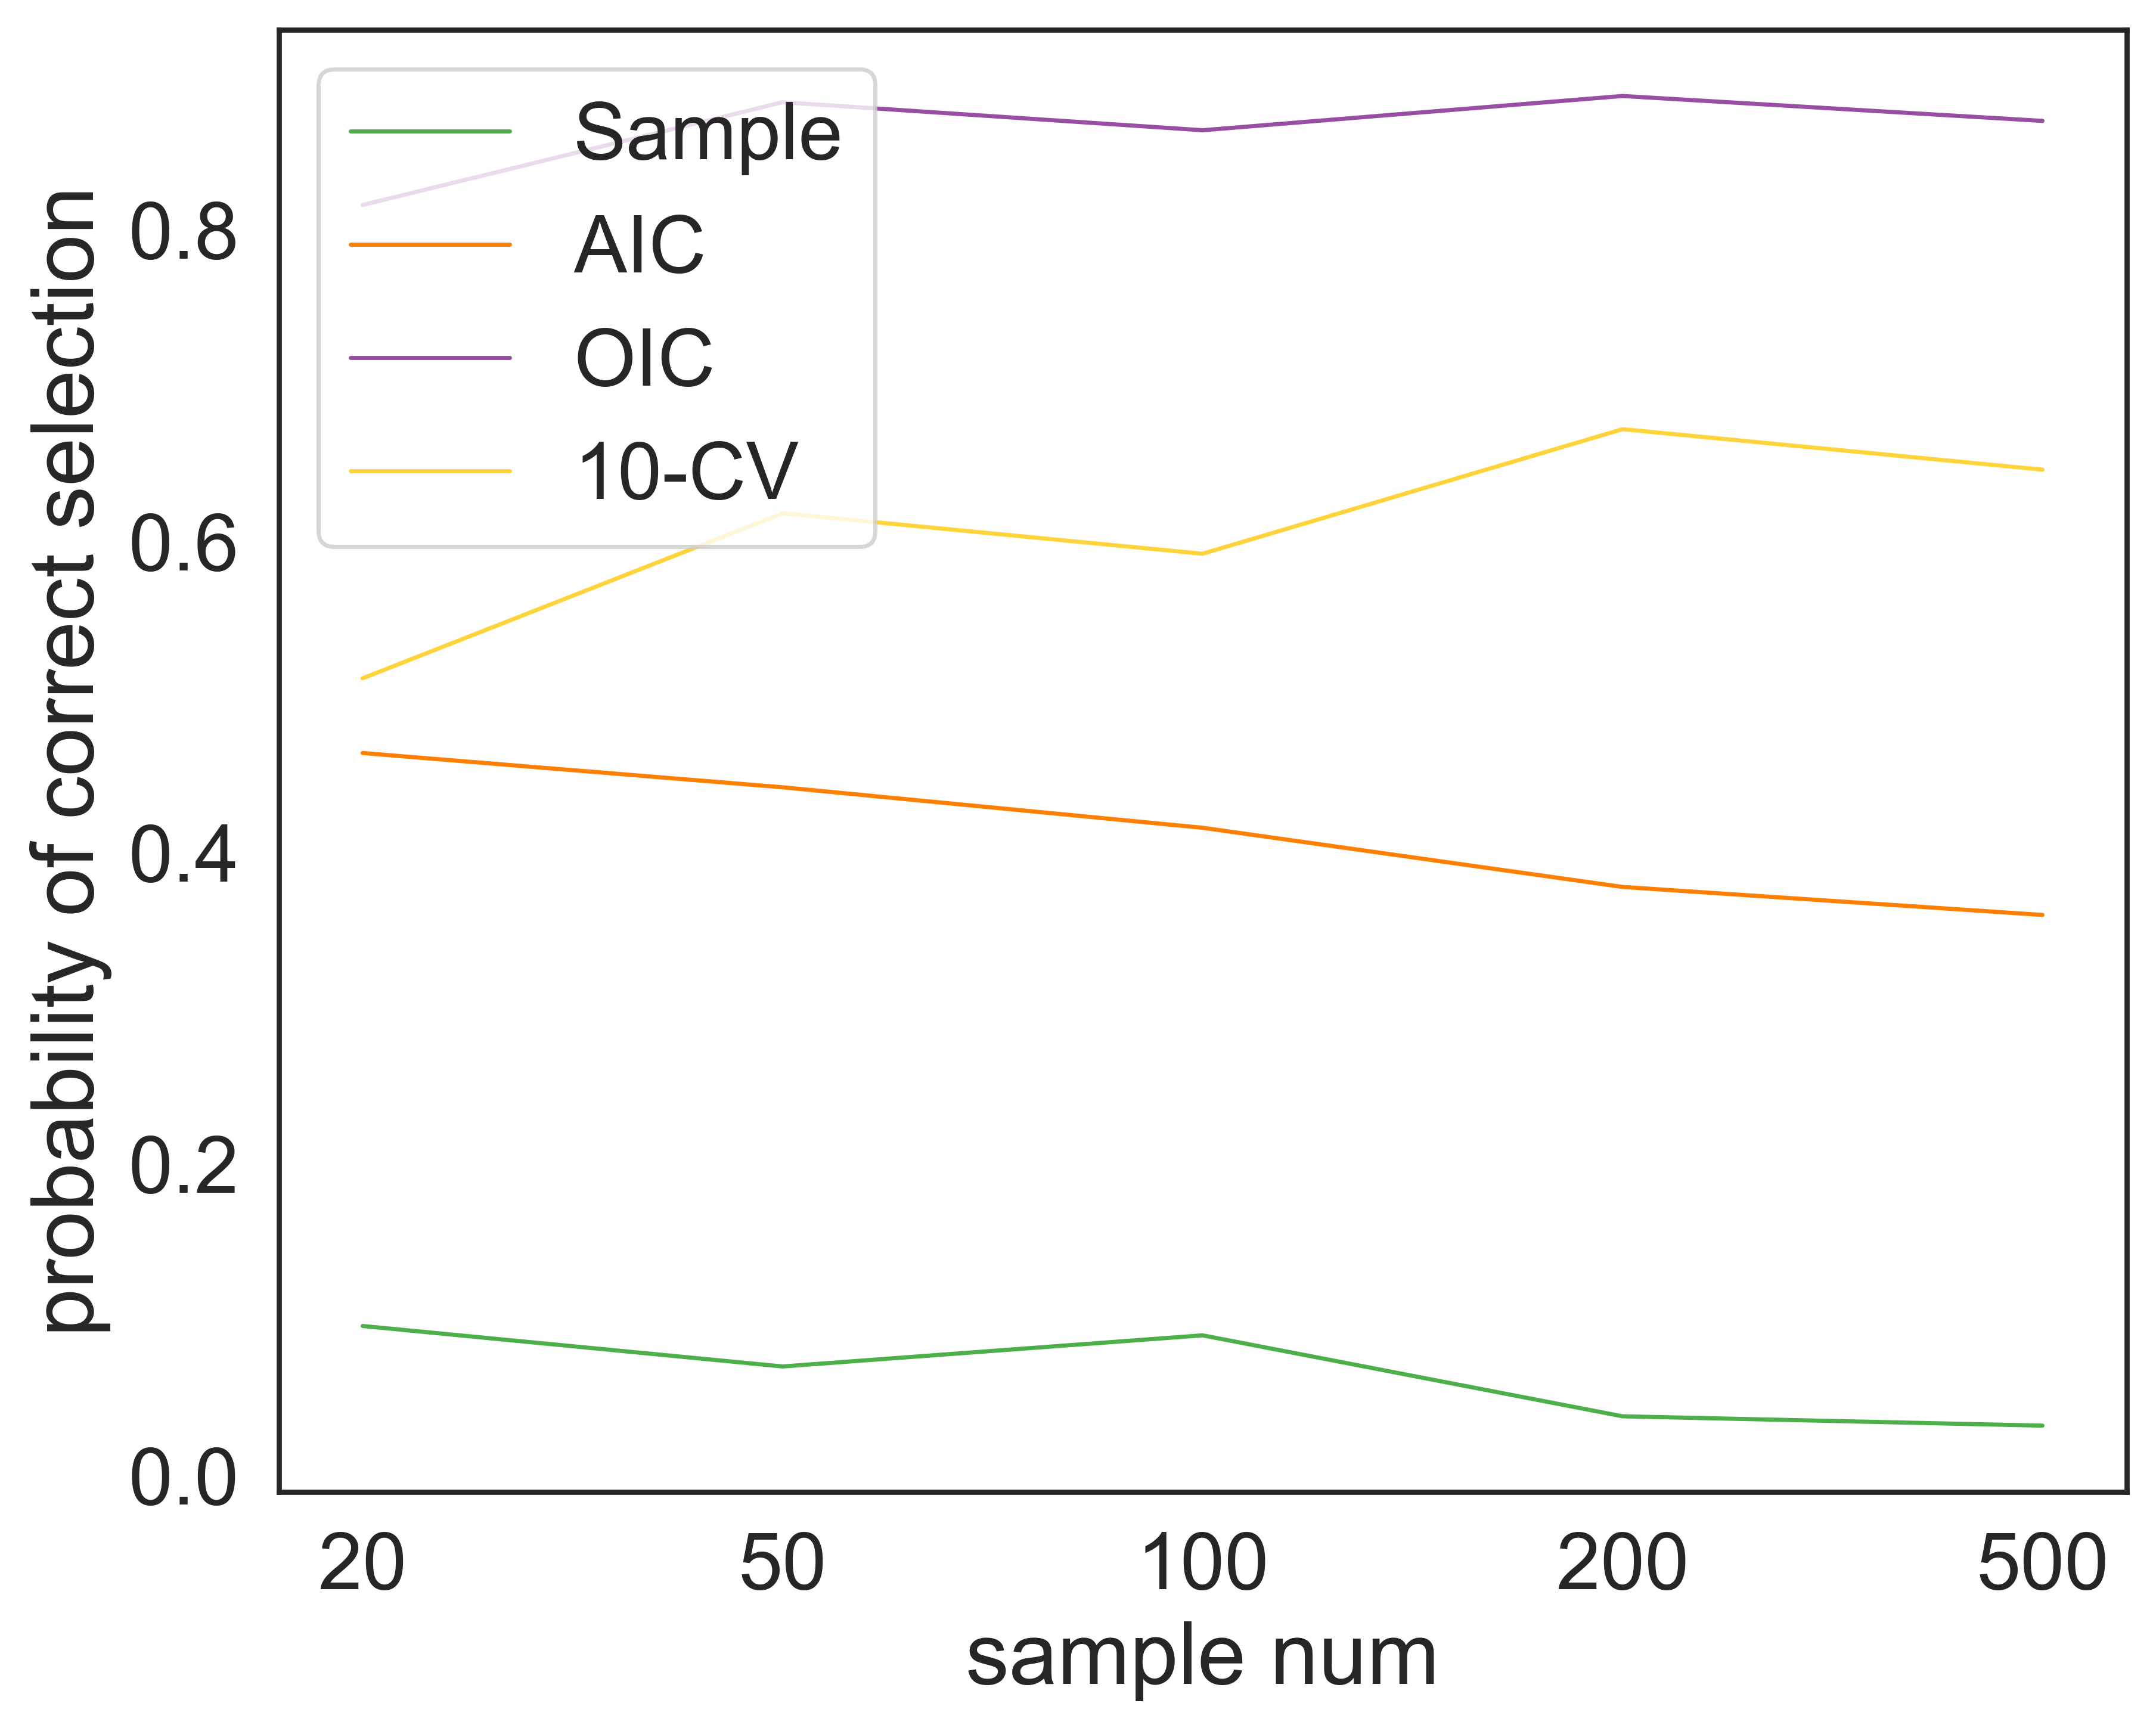

In [2]:
## visualization


import seaborn as sns
import matplotlib
import matplotlib.pyplot as plt

model_name = ['Sample', 'AIC', 'OIC', '10-CV']
sns.set(style = 'white', font_scale = 1.75)
fig, ax = plt.subplots(figsize = (8, 6.5), dpi = 500)
plt.rc("axes.spines", top = False, right = False)
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
model_prob

colors=['#4daf4a', '#ff7f00', '#984ea3', '#FFD43B', '#a65628', '#f781bf', '#e41a1c', '#377eb8']

for i in range(4):
    #model_index = i
    plt.plot([0, 1, 2, 3, 4], model_prob[:,i], label = model_name[i], color = colors[i], linewidth = 1) 
    #plt.errorbar(x = rho_list, y = final_perform_mean[model_index], yerr = final_perform_std[model_index] / math.sqrt(outer_num), color = colors[i], capsize = 2)

plt.legend(loc = 'upper left')
plt.xticks([0,1,2,3,4], [20, 50, 100, 200, 500])
plt.xlabel('sample num')
#ax.set_yticks([-5.8, -5.7, -5.6])
plt.ylabel('probability of correct selection')
plt.savefig('newfigs/test_selection2.pdf')


## Portfolio Selection with Constraint Sizes

In [2]:
from sklearn.model_selection import KFold
import cvxpy as cp

def saa_sol(data, a, gamma):
    n, d = data.shape
    Q = np.zeros((d, d))
    for i in range(n):
        Q += np.outer(data[i] - a, data[i] - a)
    Q /= n

    c = -np.mean(data, axis=0)

    # Define CVXPY variable
    x = cp.Variable(d)

    # Objective function: (1/2) * x^T Q x + c^T x
    objective = cp.Minimize(0.5 * cp.quad_form(x, Q) + c @ x)

    # Constraints
    constraints = [
    # cp.sum(x) == 1,           # Equality constraint
        x >= -gamma               # Inequality constraint
    ]
    pass

    problem = cp.Problem(objective, constraints)

    # Solve the problem
    problem.solve()

    return x.value

def empirical_eval(x, a, ood_data):
    n, d = ood_data.shape
    Q = np.zeros((d, d))
    for i in range(n):
        Q += np.outer(ood_data[i] - a, ood_data[i] - a)
    Q /= n
    c = - np.mean(ood_data, axis = 0)
    return 1/2 * x.T @ Q @ x + c @ x



def cross_validation(data, a, gamma, fold_num):
    kf = KFold(n_splits = fold_num)
    model_val = 0
    for (train_index, test_index) in kf.split(data):
        train_data, test_data = data[train_index], data[test_index]
        sol = saa_sol(train_data, a, gamma)
        model_val += empirical_eval(sol, a, test_data) / fold_num
    return model_val
        



In [56]:
import cvxpy as cp
import numpy as np

# Problem parameters
n = 50  # Number of data points
d = 5   # Dimension of x



loop_num = 200


gamma_range = [-0.2, -0.1, 0, 0.1, 0.2]

model_perform = np.zeros((loop_num, len(gamma_range), 4))
model_perform_all = {}
for k in range(loop_num):
    # Randomly generate data points
    #np.random.seed(0)
    xi = np.random.randn(n, d)  # Data points
    a = np.random.randn(d)      # Vector 'a'



    def true_cost(x, a):
        n = 50000
        xi = np.random.randn(n, d)
        Q = np.zeros((d, d))
        for i in range(n):
            Q += np.outer(xi[i] - a, xi[i] - a)
        Q /= n
        c = - np.mean(xi, axis = 0)
        return 1/2 * x.T @ Q @ x + c @ x


    for j, gamma in enumerate(gamma_range):  # Lower bound for x
        # Compute Q and c
        Q = np.zeros((d, d))
        for i in range(n):
            Q += np.outer(xi[i] - a, xi[i] - a)
        Q /= n

        c = -np.mean(xi, axis=0)

        # Define CVXPY variable
        x = cp.Variable(d)

        # Objective function: (1/2) * x^T Q x + c^T x
        objective = cp.Minimize(0.5 * cp.quad_form(x, Q) + c @ x)

        # Constraints
        constraints = [
        # cp.sum(x) == 1,           # Equality constraint
            x >= -gamma               # Inequality constraint
        ]

        # Define the problem
        problem = cp.Problem(objective, constraints)

        # Solve the problem
        problem.solve()

        # Output the results
        if problem.status == cp.OPTIMAL:
            print("Optimal solution:")
            print("x* =", x.value)

            # Dual variables (Lagrange multipliers)
            # 1. Equality constraint multiplier (lambda)
            #lambda_mult = constraints[0].dual_value
            #print("Lagrange multiplier for sum constraint (lambda):", lambda_mult)

            # 2. Inequality constraint multipliers (mu)
            mu_mult = constraints[0].dual_value
            #print("Lagrange multipliers for bound constraints (mu):", mu_mult)
            nonzero_indice = np.where(mu_mult > 0)[0]
            if len(nonzero_indice) != 0:
                C = np.zeros((len(nonzero_indice), d))
                for i in range(len(C)):
                    C[i][nonzero_indice[i]] = 1
                #print(C)
                Phi = np.identity(d) - C.T @ np.linalg.pinv(C @ C.T) @ C
            else:
                Phi = np.identity(d)
        else:
            print("The problem could not be solved.")

        x = x.value


        import numpy as np

        # Compute the Hessian (H)
        H = np.zeros((d, d))
        for i in range(n):
            H += 1 * np.outer(xi[i] - a, xi[i] - a)
        H /= n

        # Compute the expected outer product of gradients (E_P[grad grad^T])
        grad_outer = np.zeros((d, d))
        for i in range(n):
            diff = (xi[i] - a).reshape(-1, 1)  # Ensure 2D shape
            grad_i = 1 * np.dot(diff.T, x).flatten() - xi[i]  # Gradient as a 1D vector
            grad_outer += np.outer(grad_i, grad_i)
        grad_outer /= n




        model_perform[k][j][0] = problem.value + 1 * np.trace(np.linalg.pinv(Phi @ H @ Phi) @ grad_outer) / n
        model_perform[k][j][1] = problem.value
        model_perform[k][j][2] = true_cost(x, a)
        model_perform[k][j][3] = cross_validation(xi, a, gamma, 5)

        
model_perform_all[n] = model_perform


with open(f'output/port_selection/test2_{n}_{d}.npy', 'wb') as f: # loop_num = 200
    np.save(f, model_perform)



Optimal solution:
x* = [0.2 0.2 0.2 0.2 0.2]
Optimal solution:
x* = [0.1        0.16635426 0.19007716 0.1        0.1       ]
Optimal solution:
x* = [7.56134813e-24 1.85608016e-01 2.09790143e-01 9.93525866e-25
 4.43740057e-25]
Optimal solution:
x* = [-0.03999632  0.19493016  0.21980789 -0.03325232 -0.1       ]
Optimal solution:
x* = [-0.04031102  0.19543314  0.22035288 -0.02576093 -0.13200302]
Optimal solution:
x* = [0.20141752 0.2        0.2        0.2        0.33582278]
Optimal solution:
x* = [0.1        0.1        0.1        0.1        0.21492164]
Optimal solution:
x* = [-3.69431441e-25  6.22007839e-24  1.36133069e-02  2.24397980e-02
  1.06345011e-01]
Optimal solution:
x* = [-0.01796125 -0.1         0.04296813  0.09413737  0.1092657 ]
Optimal solution:
x* = [-0.01864312 -0.11295825  0.04689285  0.10359743  0.11014011]
Optimal solution:
x* = [0.2        0.2        0.2        0.36616392 0.2       ]
Optimal solution:
x* = [0.1        0.1        0.1        0.21319504 0.1       ]
Optimal 

KeyboardInterrupt: 

Text(0, 0.5, 'avg performance')

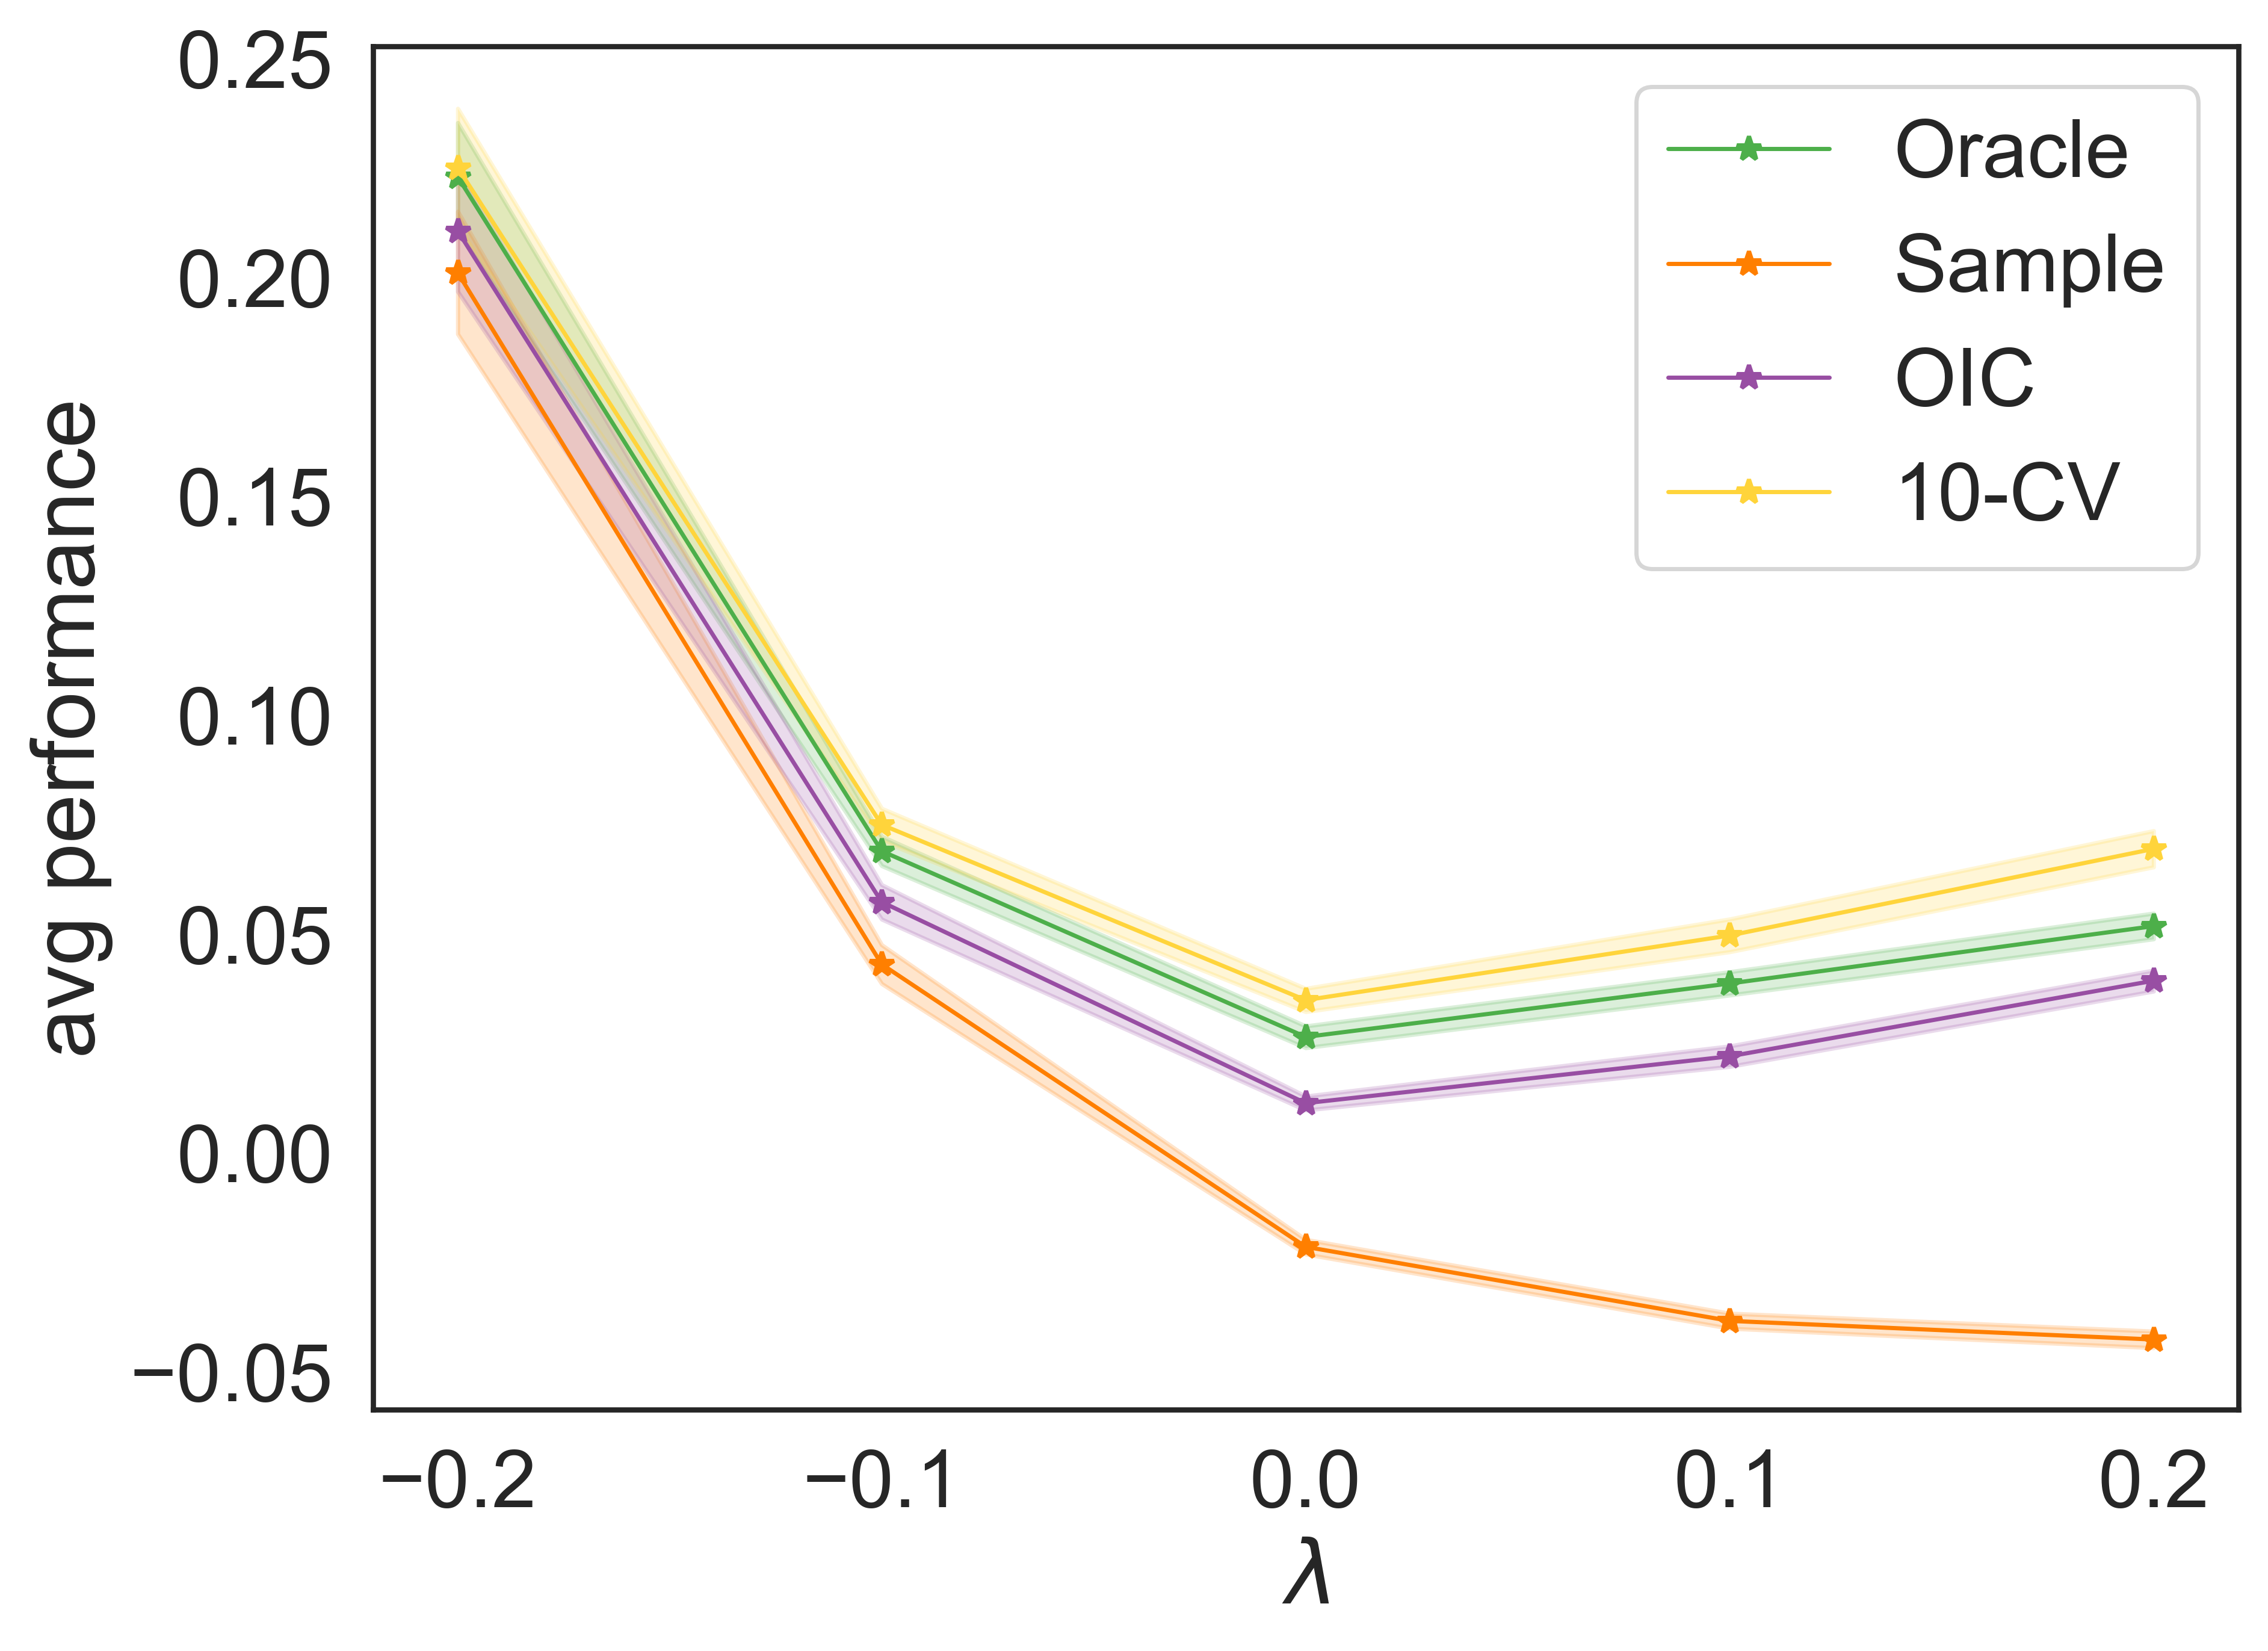

In [12]:
import seaborn as sns
import matplotlib
import numpy as np
import matplotlib.pyplot as plt
import math

gamma_range = [-0.2, -0.1, 0, 0.1, 0.2]

n, d = 50, 5
loop_num = 200

sns.set(style = 'white', font_scale = 1.75)
fig, ax = plt.subplots(figsize = (8, 6), dpi = 500)
plt.rc("axes.spines", top = False, right = False)
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42


model_perform = np.load(f'output/port_selection/test2_{n}_{d}.npy', allow_pickle = True)

sns.set(style = 'white', font_scale = 1.75)

model_name = ['Oracle', 'Sample', 'OIC', '10-CV']
#['OIC', 'Sample', 'Oracle', '10-CV']
['Oracle', 'Sample', 'OIC', '10-CV']
true_model_perform = np.zeros((4,5))
true_model_err_perform = np.zeros((4, 5))
for j in range(4):
    true_model_perform[j] = np.array([np.mean(model_perform[:,i,j]) for i in range(5)])
    true_model_err_perform[j] = np.array([np.std(model_perform[:,i,j]) / math.sqrt(loop_num) for i in range(5)])

colors=['#4daf4a', '#ff7f00', '#984ea3', '#FFD43B', '#a65628', '#f781bf', '#e41a1c', '#377eb8']

for i, k in enumerate([2,1,0,3]):
    #model_index = i
    plt.errorbar([-0.2,-0.1,0,0.1,0.2], true_model_perform[k], label = model_name[i], marker = '*', color = colors[i], linewidth = 1) 
    plt.fill_between([-0.2,-0.1,0,0.1,0.2], true_model_perform[k] - true_model_err_perform[k], true_model_perform[k] + true_model_err_perform[k], alpha = 0.2, color = colors[i])
    #plt.errorbar(x = rho_list, y = final_perform_mean[model_index], yerr = final_perform_std[model_index] / math.sqrt(outer_num), color = colors[i], capsize = 2)

plt.legend(loc = 'upper right')
plt.xlabel(r'$\lambda$')
#ax.set_yticks([-5.8, -5.7, -5.6])
plt.ylabel('avg performance')
#plt.savefig('newfigs/constrain_select.pdf', bbox_inches = 'tight')

